<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/Conventional_vs_High_Kinetic_Inductance_Superconducting_QHO_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# Conventional and High Kinetic Inductance Superconducting Quantum Harmonic Oscillators

## 1. Motivation

A compact superconducting resonator draws part of its inductance from the collective motion of superconducting charge carriers, linking material properties directly to its quantum fluctuations. Increasing this kinetic contribution changes the resonance frequency and redistributes fluctuations between circuit flux and capacitor charge, creating a design tradeoff between excitation energy and fluctuation amplitude. Holding capacitance and geometric inductance fixed isolates that tradeoff, permitting a controlled comparison between conventional and high kinetic inductance examples. Their potential landscapes and Wigner distributions describe the resulting collective electromagnetic modes, whose excitations form harmonic energy ladders. A separate superconducting lattice calculation resolves fermionic quasiparticles, placing the circuit behavior alongside the microscopic pairing physics that supports superconductivity [1–3].

## 2. Notation and Terminology

Energy exchange between an inductor and a capacitor selects circuit flux and charge as conjugate coordinates, giving the collective mode a continuous phase space. Electron–hole mixing introduces a second description at the microscopic scale, with pairing and hopping energies characterizing quasiparticles independently of the assigned circuit inductances.

| Symbol or abbreviation | Definition and physical role | Units or convention |
|:---|:---|:---|
| QHO | Quantum harmonic oscillator | Equally spaced excitation ladder |
| HKI | High kinetic inductance | A circuit or material regime with a large kinetic contribution |
| LC | Inductor–capacitor circuit | Single lumped electromagnetic mode |
| BdG | Bogoliubov–de Gennes | Mean-field electron–hole Hamiltonian |
| QuTiP | Quantum Toolbox in Python | Quantum-state calculations and Wigner functions |
| $C$ | Effective capacitance of the circuit mode | Farad |
| $L_{\mathrm{geo}}$, $L_{\mathrm{kin}}$, $L_{\mathrm{tot}}$ | Geometric, kinetic, and total mode inductances | Henry |
| $\alpha_{\mathrm{kin}}$ | Kinetic fraction of the total inductance | Dimensionless |
| $\Phi$, $Q$ | Generalized circuit flux and capacitor charge | Weber, coulomb |
| $\hat\Phi$, $\hat Q$ | Quantum operators associated with circuit flux and charge | Weber, coulomb |
| $t$, $t_{\mathrm{ref}}$, $V_{\mathrm{el}}$ | Time, reference time, and circuit voltage | Second, second, volt |
| $I$, $U_L$, $V(\Phi)$ | Circuit current, total inductive energy, and flux-dependent potential energy | Ampere, joule, joule |
| $\hat H$, $\hat a$, $\hat a^\dagger$ | Circuit Hamiltonian, mode annihilation operator, and mode creation operator | Joule; dimensionless ladder operators |
| $\omega$, $f$, $Z$ | Angular resonance frequency, resonance frequency, and mode impedance | Radian per second, hertz, ohm |
| $n$, $\lvert n\rangle$, $E_n$ | Oscillator occupation number, number state, and corresponding circuit energy | Nonnegative integer, state vector, joule |
| $\delta E$ | Separation of neighboring oscillator energies | Joule |
| $\Phi_{\mathrm{zpf}}$, $Q_{\mathrm{zpf}}$ | Ground-state standard deviations of flux and charge, called zero-point fluctuation amplitudes | Weber, coulomb |
| $\Delta\Phi$, $\Delta Q$ | Flux and charge standard deviations in a specified state | Weber, coulomb |
| $\psi_n(\Phi)$, $H_n$ | Normalized flux wavefunction and physicists' Hermite polynomial | $\mathrm{Wb}^{-1/2}$; polynomial |
| $\xi$, $x$, $p$ | Dimensionless wavefunction coordinate and dimensionless flux–charge quadratures | Dimensionless; $p$ is a charge quadrature |
| $\Phi_{\mathrm{turn},n}$ | Positive classical turning flux at oscillator energy $E_n$ | Weber |
| $\mathcal E_n(\Phi)$, $s_{\mathrm{plot}}$ | Displayed density curve and its graphical scale factor | Joule, joule–weber |
| $W_0(x,p)$, $W_0(\Phi,Q)$ | Ground-state Wigner densities in dimensionless and physical coordinates | Dimensionless, inverse action |
| $D$ | Truncated oscillator Hilbert-space dimension | $30$ number states |
| $\mu_0$, $\lambda_L$ | Vacuum permeability and London penetration depth | Henry per meter, meter |
| $\ell$, $w$, $d$ | Superconducting strip length, width, and thickness | Meter |
| $R_\square$ | Normal-state sheet resistance of a superconducting film | Ohm per square |
| $T$, $k_{\mathrm B}$, $\bar n_{\mathrm{th}}$ | Equilibrium temperature, Boltzmann constant, and mean thermal oscillator occupation | Kelvin, joule per kelvin, dimensionless |
| $h$, $\hbar$ | Planck constant and reduced Planck constant, with $\hbar:=h/(2\pi)$ | Joule–second |
| $e$, $R_Q$ | Positive elementary charge and superconducting resistance quantum | Coulomb, ohm |
| $N$, $j$, $m$ | Lattice site count, site index, and normal-mode index | $N=60$; $j,m=1,\ldots,N$ |
| $\mathsf H_{jj}$, $\mathsf H_{j,j+1}$ | On-site and neighboring-site blocks of the BdG Hamiltonian | Electronvolt in the lattice calculation |
| $t_{\mathrm{hop}}$, $\mu$, $\Delta$ | Nearest-neighbor hopping energy, chemical potential, and real superconducting pairing amplitude | Electronvolt in the lattice calculation |
| $\tau_x$, $\tau_z$ | Pauli matrices acting in the electron–hole sector | Dimensionless |
| $\varepsilon_m$, $E_{m,\pm}$ | Normal-state mode energy and paired BdG eigenenergies | Electronvolt in the lattice calculation |
| $i$, $\pi$, $\exp$ | Imaginary unit, circle constant, and exponential function | Standard mathematical conventions |

Throughout the comparison, the subscripts $\mathrm{conv}$ and $\mathrm{HKI}$ identify the conventional and high kinetic inductance parameter sets. Operator notation uses a hat, Hermitian conjugation uses a dagger, and angle brackets denote a quantum expectation value; an unattached $\Delta$ denotes the pairing amplitude, distinguishing it from observable standard deviations.

## 3. First Principles: Quantization of a Superconducting Circuit Mode

Magnetic-field energy and condensate kinetic energy respond to the same circuit current, allowing both contributions to enter one linear energy-storage model. For a shared current path representing a single effective mode, their sum defines the **total inductance** [1,2].

$$
L_{\mathrm{tot}}:=L_{\mathrm{geo}}+L_{\mathrm{kin}}.\qquad (1)
$$

Voltage supplies a circuit-level measure of that inductive response, including the contribution associated with carrier motion. Integrating the voltage defines the **generalized circuit flux**, with $t_{\mathrm{ref}}$ selecting the reference at which the coordinate vanishes.

$$
\Phi(t):=\int_{t_{\mathrm{ref}}}^{t}V_{\mathrm{el}}(t')\,\mathrm{d}t'.\qquad (2)
$$

Under a constant linear inductance, the generalized flux is proportional to current. Its dependence on the total inductance includes condensate kinetic energy, extending the coordinate beyond the magnetic-field flux associated with conductor geometry alone.

$$
\Phi=L_{\mathrm{tot}} I.\qquad (3)
$$

Expressing the stored inductive energy in terms of flux produces the parabolic confinement visible in the potential plots. A larger total inductance reduces the energy cost of a specified flux displacement, setting the curvature of this potential.

$$
V(\Phi):=U_L=\frac{1}{2}L_{\mathrm{tot}} I^2=\frac{\Phi^2}{2L_{\mathrm{tot}}}.\qquad (4)
$$

Capacitive storage completes the oscillator by assigning an energy cost to accumulated electric charge. Combining the capacitive and inductive contributions gives the **circuit Hamiltonian** for an isolated, lossless, single linear mode [1].

$$
\hat H:=\frac{\hat Q^2}{2C}+\frac{\hat\Phi^2}{2L_{\mathrm{tot}}}.\qquad (5)
$$

Flux and charge acquire their quantum relationship as canonically conjugate operators. The corresponding commutator fixes the action scale governing their joint uncertainty, independent of the numerical choices of capacitance and inductance.

$$
[\hat\Phi,\hat Q]=i\hbar.\qquad (6)
$$

Oscillation follows from the exchange between the two quadratic energy contributions, with the classical circuit equation determining its characteristic rate. That rate defines the **angular resonance frequency**, which also controls the spacing of the quantized excitation ladder.

$$
\omega:=\frac{1}{\sqrt{L_{\mathrm{tot}} C}}.\qquad (7)
$$

Microwave spectroscopy expresses the same oscillation rate in cycles per second, defining the laboratory resonance frequency.

$$
f:=\frac{\omega}{2\pi}.\qquad (8)
$$

Frequency specifies the energy exchanged per excitation, although it leaves the relative sizes of flux and charge fluctuations undetermined. Their balance depends on the **mode impedance**, which compares inductive storage with capacitive storage.

$$
Z:=\sqrt{\frac{L_{\mathrm{tot}}}{C}}.\qquad (9)
$$

Diagonalizing the quadratic Hamiltonian introduces number states, in which each additional collective excitation contributes the same energy. The operator $\hat a^\dagger\hat a$ counts these excitations, giving the Hamiltonian its number-state representation.

$$
\hat H=\hbar\omega\left(\hat a^\dagger\hat a+\frac{1}{2}\right).\qquad (10)
$$

Occupation $n$ specifies a number state's definite energy, with the vacuum holding a nonzero zero-point contribution. The resulting **oscillator energy levels** are

$$
E_n:=\hbar\omega\left(n+\frac{1}{2}\right),\qquad n=0,1,2,\ldots.\qquad (11)
$$

Equal separation between adjacent levels identifies the defining spectral property of the harmonic mode. This separation is the energy of one circuit photon, linking the quantum ladder directly to the measured resonance frequency.

$$
\delta E:=E_{n+1}-E_n=\hbar\omega=hf.\qquad (12)
$$

## 4. Implementation and Scaling: Potential Landscapes and Quantum Fluctuations

Both examples use a $100\,\mathrm{fF}$ capacitance and a $1\,\mathrm{nH}$ geometric inductance, fixing the capacitive energy scale and the magnetic contribution to inductive storage. Raising the kinetic inductance from $0.05\,\mathrm{nH}$ to $5\,\mathrm{nH}$ softens the flux confinement, accounting for the lower and more closely spaced levels in the right-hand potential plot.

Carrier motion accounts for a fraction of the total inductive energy, quantifying how strongly this parameter change alters the mode's physical composition. For the shared-current model, the **kinetic inductance fraction** is

$$
\alpha_{\mathrm{kin}}:=\frac{L_{\mathrm{kin}}}{L_{\mathrm{tot}}}.\qquad (13)
$$

| Circuit quantity | Conventional example | High kinetic inductance example |
|:---|---:|---:|
| $C$ | $100\,\mathrm{fF}$ | $100\,\mathrm{fF}$ |
| $L_{\mathrm{geo}}$ | $1.00\,\mathrm{nH}$ | $1.00\,\mathrm{nH}$ |
| $L_{\mathrm{kin}}$ | $0.05\,\mathrm{nH}$ | $5.00\,\mathrm{nH}$ |
| $L_{\mathrm{tot}}$ | $1.05\,\mathrm{nH}$ | $6.00\,\mathrm{nH}$ |
| $\alpha_{\mathrm{kin}}$ | $0.04762$ | $0.83333$ |
| $f$ | $15.5319\,\mathrm{GHz}$ | $6.49747\,\mathrm{GHz}$ |
| $Z$ | $102.470\,\Omega$ | $244.949\,\Omega$ |
| $\delta E$ | $1.02916\times10^{-23}\,\mathrm{J}$ | $4.30527\times10^{-24}\,\mathrm{J}$ |
| $\delta E$ in electronvolts | $64.2349\,\mu\mathrm{eV}$ | $26.8714\,\mu\mathrm{eV}$ |
| $\Phi_{\mathrm{zpf}}$ | $7.35056\times10^{-17}\,\mathrm{Wb}$ | $1.13648\times10^{-16}\,\mathrm{Wb}$ |
| $Q_{\mathrm{zpf}}$ | $7.17341\times10^{-19}\,\mathrm{C}$ | $4.63965\times10^{-19}\,\mathrm{C}$ |

Tabulated energy spacings locate the eigenstates vertically, and their flux-dependent probability densities determine the shapes of the filled profiles. In the flux representation, assigning charge the differential operator $\hat Q=-i\hbar\,\partial/\partial\Phi$ converts equation (5) into the stationary circuit Schrödinger equation.

$$
\left[-\frac{\hbar^2}{2C}\frac{\mathrm{d}^2}{\mathrm{d}\Phi^2}+\frac{\Phi^2}{2L_{\mathrm{tot}}}\right]\psi_n(\Phi)=E_n\psi_n(\Phi).\qquad (14)
$$

Competition between the derivative energy and the parabolic confinement sets the width of the ground-state Gaussian. Its flux standard deviation defines the **flux zero-point fluctuation amplitude**, which increases with mode impedance.

$$
\Phi_{\mathrm{zpf}}:=\sqrt{\langle0|\hat\Phi^2|0\rangle}=\sqrt{\frac{\hbar Z}{2}}.\qquad (15)
$$

Charge fluctuations in the same ground state have a distribution whose width responds inversely to impedance. Its standard deviation defines the **charge zero-point fluctuation amplitude**, completing the pair of vacuum fluctuation scales.

$$
Q_{\mathrm{zpf}}:=\sqrt{\langle0|\hat Q^2|0\rangle}=\sqrt{\frac{\hbar}{2Z}}.\qquad (16)
$$

Normalizing circuit flux by the Gaussian width removes the device-dependent units from the eigenfunction problem. The resulting dimensionless coordinate $\xi$ permits the probability profiles to share a common Hermite-polynomial form.

$$
\xi:=\frac{\Phi}{\sqrt{2}\Phi_{\mathrm{zpf}}}.\qquad (17)
$$

Excited-state structure enters via the physicists' Hermite polynomial $H_n$, whose zeros determine the nodes in the flux probability distribution. Including its normalization gives the density used for each filled profile.

$$
|\psi_n(\Phi)|^2=\frac{H_n(\xi)^2\exp(-\xi^2)}{\sqrt{2\pi}\Phi_{\mathrm{zpf}}\,2^n n!}.\qquad (18)
$$

Classical motion at a specified eigenenergy reaches its largest flux displacement at the potential-energy boundary. Equating that potential to $E_n$ defines the positive **classical turning flux**, locating the endpoints of the dashed energy segments.

$$
\Phi_{\mathrm{turn},n}:=\sqrt{2L_{\mathrm{tot}} E_n}.\qquad (19)
$$

Filled profiles place each normalized probability density above its corresponding eigenenergy, allowing occupation-dependent spatial structure and energy spacing to appear on the same axes. Their vertical displacement uses a graphical scale factor $s_{\mathrm{plot}}$, assigned independently in each column with units of joule–weber. Choosing this factor gives the ground-state profile a peak height of $0.7\hbar\omega$ above its baseline, defining the displayed curve as

$$
\mathcal E_n(\Phi):=E_n+s_{\mathrm{plot}}|\psi_n(\Phi)|^2.\qquad (20)
$$

Fixing capacitance isolates the inductive dependence of all four characteristic scales. Combining equations (7), (9), (15), and (16) yields the frequency, impedance, and zero-point amplitude scalings.

$$
\omega\propto L_{\mathrm{tot}}^{-1/2},\qquad Z\propto L_{\mathrm{tot}}^{1/2},\qquad\Phi_{\mathrm{zpf}}\propto L_{\mathrm{tot}}^{1/4},\qquad Q_{\mathrm{zpf}}\propto L_{\mathrm{tot}}^{-1/4}.\qquad (21)
$$

Across the two examples, the total inductance increases by a factor of $5.71429$, lowering the frequency to $0.41833$ of its conventional value and raising the impedance by a factor of $2.39046$. The associated flux standard deviation grows by a factor of $1.54611$, accompanied by a charge standard deviation reduced to $0.64678$ of its conventional value. These reciprocal changes account quantitatively for the wider flux distribution and narrower charge distribution on the shared physical axes.

## 5. Advanced Phenomena: Phase Space and Superconducting Quasiparticles

Redistribution of vacuum fluctuations changes the shape of the phase-space distribution without changing its minimum-uncertainty character. Electron–hole mixing addresses a separate physical question by opening a microscopic quasiparticle gap, whose assigned value does not set the circuit impedance.

For each oscillator's ground state, multiplying the two zero-point amplitudes cancels the impedance dependence. Their product saturates the canonical uncertainty bound.

$$
\Delta\Phi\,\Delta Q=\Phi_{\mathrm{zpf}}Q_{\mathrm{zpf}}=\frac{\hbar}{2}.\qquad (22)
$$

QuTiP represents the vacuum as $\lvert0\rangle$ in a $D=30$ number-state basis and evaluates its Wigner distribution in dimensionless quadratures [4]. The horizontal coordinate follows from normalizing physical flux by its own mode's zero-point scale.

$$
x:=\frac{\Phi}{\sqrt{2}\Phi_{\mathrm{zpf}}}.\qquad (23)
$$

Rescaling charge by its conjugate zero-point scale supplies the vertical coordinate. Here, $p$ denotes a dimensionless charge quadrature, preserving the circuit interpretation of the underlying physical variable.

$$
p:=\frac{Q}{\sqrt{2}Q_{\mathrm{zpf}}}.\qquad (24)
$$

These mode-specific coordinates absorb the impedance dependence into the axis transformation. Both ground states share the same circular **vacuum Wigner function**.

$$
W_0(x,p):=\frac{1}{\pi}\exp(-x^2-p^2).\qquad (25)
$$

Returning to physical flux and charge changes the phase-space area element, requiring a Jacobian in the Wigner density. Equation (22) fixes that Jacobian at $\hbar$, giving the physically normalized distribution as

$$
W_0(\Phi,Q):=\frac{1}{\pi\hbar}\exp\left[-\frac{\Phi^2}{2\Phi_{\mathrm{zpf}}^2}-\frac{Q^2}{2Q_{\mathrm{zpf}}^2}\right].\qquad (26)
$$

Color values in the plotted distributions preserve QuTiP's dimensionless normalization, although the displayed axes carry physical units. Dividing those values by $\hbar$ gives the density in equation (26), ensuring normalization over physical flux and charge.

Each distribution represents its own oscillator's unsqueezed vacuum, with the different physical widths arising from the impedance-dependent coordinate transformation. Expressing both states in a common reference mode's quadratures describes their relative deformation as squeezing, preserving the uncertainty product in equation (22). Their Gaussian form and pure-state character accompany the reciprocal changes in flux and charge fluctuations.

White margins originate from the finite numerical grids, each of which spans dimensionless coordinates from $-4$ to $4$. Conversion to physical units gives the two grids different extents, leaving uncomputed margins under the shared axis limits.

At the microscopic scale, Kwant constructs an open chain of $N=60$ sites with two electron–hole components at each site [5]. A real pairing amplitude $\Delta$ mixes those components in the **on-site BdG block**, with the chemical potential $\mu$ measured relative to the normal-state band minimum.

$$
\mathsf H_{jj}:=(2t_{\mathrm{hop}}-\mu)\tau_z+\Delta\tau_x.\qquad (27)
$$

Propagation along the chain involves nearest-neighbor hopping, whose electron and hole contributions carry opposite signs. This structure gives the **hopping block**, with the reverse connection supplied by its Hermitian conjugate.

$$
\mathsf H_{j,j+1}:=-t_{\mathrm{hop}}\tau_z.\qquad (28)
$$

Open boundaries restrict the uniform normal-state chain to standing-wave modes. Their allowed spatial structure diagonalizes the hopping problem, yielding the following normal-mode energies.

$$
\varepsilon_m:=2t_{\mathrm{hop}}\left[1-\cos\left(\frac{m\pi}{N+1}\right)\right]-\mu,\qquad m=1,\ldots,N.\qquad (29)
$$

Uniform pairing then couples each normal mode to its hole partner, converting its normal-state energy into a pair of superconducting eigenenergies. The resulting expression reproduces the $2N=120$ eigenvalues obtained by numerical diagonalization.

$$
E_{m,\pm}:=\pm\sqrt{\varepsilon_m^2+\Delta^2}.\qquad (30)
$$

| Microscopic quantity | Conventional example | High kinetic inductance example |
|:---|---:|---:|
| $N$ | $60$ | $60$ |
| $t_{\mathrm{hop}}$ | $1.00\,\mathrm{eV}$ | $0.20\,\mathrm{eV}$ |
| $\mu$ | $0.10\,\mathrm{eV}$ | $0.10\,\mathrm{eV}$ |
| $\Delta$ | $0.10\,\mathrm{eV}$ | $0.25\,\mathrm{eV}$ |
| Lowest positive BdG eigenenergy | $0.100139\,\mathrm{eV}$ | $0.2500004\,\mathrm{eV}$ |
| Largest positive BdG eigenenergy | $3.89863\,\mathrm{eV}$ | $0.742804\,\mathrm{eV}$ |

Reducing the hopping directly narrows the normal-state bandwidth, concentrating the quasiparticle spectrum within a smaller total energy range. Increasing the independently assigned pairing amplitude enlarges the separation between positive and negative branches, placing the finite-chain gap edges at or outside $\pm\Delta$. The red dashed lines identify the continuum pairing edges, and the horizontal state index orders the calculated eigenvalues.

Negative BdG eigenvalues encode the particle–hole partner branch associated with positive-energy quasiparticle excitations. In the bulk limit, the electron–hole spectral gap spans approximately $2\Delta$, setting a microscopic energy scale separate from the collective photon spacing $\hbar\omega$. The assigned pairing amplitudes of $0.10\,\mathrm{eV}$ and $0.25\,\mathrm{eV}$ define illustrative lattice energy scales; material-specific gap estimates require independently characterized superconducting parameters.

Separate assignments specify the microscopic energies and total inductances associated with the shared parameter-set labels. A uniform reduction of $t_{\mathrm{hop}}$ changes the coherent band structure, leaving the chain spatially uniform; a microscopic disorder description requires spatially varying site energies or hopping amplitudes. Connecting either spectrum to a material-derived kinetic inductance requires the superconducting current response together with conductor geometry. Superfluid stiffness and electromagnetic response supply that connection, extending the physical information beyond the quasiparticle gap alone [2,3].

## 6. Practical Application: Material Geometry, Thermal Occupation, and Measurement

Fabrication fixes conductor dimensions, making the superconducting current response responsible for the kinetic inductance supported by a given layout. Its contribution changes the mode frequency and impedance, linking material selection to microwave spectroscopy and interactions with charge-sensitive or flux-sensitive quantum systems [1,2].

Within the local London regime, a long strip carrying approximately uniform current density stores condensate kinetic energy in proportion to its length. The width and thickness set the cross-sectional area, giving the **kinetic inductance** its geometric dependence.

$$
L_{\mathrm{kin}}\simeq\mu_0\lambda_L^2\frac{\ell}{wd}.\qquad (31)
$$

Thin films with uniform isotropic s-wave pairing also admit a relation between kinetic inductance and normal-state sheet resistance in the local dirty limit [2]. Small excitation current suppresses current-dependent nonlinearities, and the low-temperature condition $k_{\mathrm B}T\ll\Delta(0)$ suppresses thermal quasiparticles. Excitation in the subgap regime $\hbar\omega\ll2\Delta(0)$ excludes direct single-photon pair breaking, permitting the low-frequency expression below. The gap in this SI-unit expression is an energy in joules.

$$
L_{\mathrm{kin}}\simeq\frac{\hbar R_\square}{\pi\Delta(0)}\frac{\ell}{w}.\qquad (32)
$$

Equation (32) exposes two separate material dependencies: increasing sheet resistance raises kinetic inductance at fixed gap and geometry, and increasing the gap lowers kinetic inductance at fixed sheet resistance and geometry. An enlarged BdG gap alone supplies no direct prediction of an enlarged kinetic inductance. Thin niobium nitride strips and granular aluminum resonators provide experimentally studied routes to large kinetic contributions [2,3].

Material-dependent current response also introduces nonlinear corrections to the linear circuit model, with granular aluminum resonators exhibiting measured Kerr shifts [3]. The present constant-inductance Hamiltonians have zero anharmonicity, giving every adjacent transition the same frequency. Their equally spaced ladders describe bosonic modes for oscillator-based quantum systems, with the different impedances determining their vacuum fluctuation amplitudes.

Lowering the resonance frequency also reduces the excitation energy that thermal fluctuations must supply. For an oscillator equilibrated with a bath at temperature $T$, the Bose–Einstein distribution gives the **mean thermal occupation**, extending the vacuum description to finite temperature.

$$
\bar n_{\mathrm{th}}:=\left[\exp\left(\frac{\hbar\omega}{k_{\mathrm B}T}\right)-1\right]^{-1}.\qquad (33)
$$

Thermal excitation has a characteristic scale $\hbar\omega/k_{\mathrm B}$ equal to $0.7454\,\mathrm{K}$ for the conventional example and $0.3118\,\mathrm{K}$ for the high kinetic inductance example. At a common bath temperature, the lower-frequency mode carries a larger equilibrium occupation, linking the kinetic-inductance choice directly to thermal preparation requirements.

Spectroscopy resolves the shifted resonance, and calibrated quadrature measurements characterize the fluctuation statistics associated with the changed impedance. Resonance linewidth and energy relaxation additionally depend on dissipation and external coupling, which enter a driven or open-system description. The kinetic fraction specifies an energy-storage contribution, leaving quality factor and coherence time dependent on those additional physical mechanisms.

Impedance provides a further reference for evaluating the extent of the circuit change. The **superconducting resistance quantum** supplies a customary comparison scale for circuits supporting large phase fluctuations.

$$
R_Q:=\frac{h}{4e^2}\simeq6.453\,\mathrm{k}\Omega.\qquad (34)
$$

Despite its dominant kinetic contribution, the high kinetic inductance example reaches approximately $245\,\Omega$, well below the superconducting resistance quantum. Reaching a superinductor regime requires consideration of total impedance together with parasitic modes, making capacitance an essential design parameter alongside the kinetic inductance.

## 7. Summary

Increasing the assigned kinetic inductance softens the collective flux potential, lowers the oscillator frequency, and redistributes vacuum fluctuations toward flux with the minimum-uncertainty product preserved. Numerically, the total inductance rises from $1.05\,\mathrm{nH}$ to $6.00\,\mathrm{nH}$, the frequency falls from $15.532\,\mathrm{GHz}$ to $6.497\,\mathrm{GHz}$, and the impedance rises from $102.47\,\Omega$ to $244.95\,\Omega$. Both collective modes possess equally spaced harmonic levels, whose fluctuation amplitudes follow their respective circuit impedances. Independently, reduced hopping and stronger assigned pairing reshape the uniform-chain BdG spectrum, characterizing a separate set of fermionic excitations. A quantitative material connection requires the superconducting current response and conductor geometry, which translate microscopic superfluid stiffness into effective circuit inductance.

## 8. References

1. A. Blais, A. L. Grimsmo, S. M. Girvin, and A. Wallraff (2021). “Circuit quantum electrodynamics.” Reviews of Modern Physics 93(2), 025005. DOI: [10.1103/RevModPhys.93.025005](https://doi.org/10.1103/RevModPhys.93.025005).

2. A. J. Annunziata, D. F. Santavicca, L. Frunzio, G. Catelani, M. J. Rooks, A. Frydman, and D. E. Prober (2010). “Tunable superconducting nanoinductors.” Nanotechnology 21(44), 445202. DOI: [10.1088/0957-4484/21/44/445202](https://doi.org/10.1088/0957-4484/21/44/445202).

3. N. Maleeva, L. Grünhaupt, T. Klein, F. Levy-Bertrand, O. Dupre, M. Calvo, F. Valenti, P. Winkel, F. Friedrich, W. Wernsdorfer, A. V. Ustinov, H. Rotzinger, A. Monfardini, M. V. Fistul, and I. M. Pop (2018). “Circuit quantum electrodynamics of granular aluminum resonators.” Nature Communications 9, 3889. DOI: [10.1038/s41467-018-06386-9](https://doi.org/10.1038/s41467-018-06386-9).

4. N. Lambert, E. Giguère, P. Menczel, B. Li, P. Hopf, G. Suárez, M. Gali, J. Lishman, R. Gadhvi, R. Agarwal, A. Galicia, N. Shammah, P. Nation, J. R. Johansson, S. Ahmed, S. Cross, A. Pitchford, and F. Nori (2026). “QuTiP 5: The Quantum Toolbox in Python.” Physics Reports 1153, 1–62. DOI: [10.1016/j.physrep.2025.10.001](https://doi.org/10.1016/j.physrep.2025.10.001).

5. C. W. Groth, M. Wimmer, A. R. Akhmerov, and X. Waintal (2014). “Kwant: a software package for quantum transport.” New Journal of Physics 16(6), 063065. DOI: [10.1088/1367-2630/16/6/063065](https://doi.org/10.1088/1367-2630/16/6/063065).

In [5]:
%%capture
# Setup 1 - Install Conda
!pip install -q condacolab
import condacolab
condacolab.install()

In [6]:
%%capture
import shutil
import subprocess
import sys

# 1. Define packages to install via Conda (Pre-compiled binaries)
CONDA_PACKAGES = [
    "kwant=1.5.0",
    "qutip",
    "tinyarray",
    "numpy",
    "scipy",
    "matplotlib",
    "threadpoolctl"
]

# 2. Install the heavy scientific dependencies
subprocess.run(
    ["conda", "install", "-y", "-q", "-c", "conda-forge", *CONDA_PACKAGES],
    check=True,
)

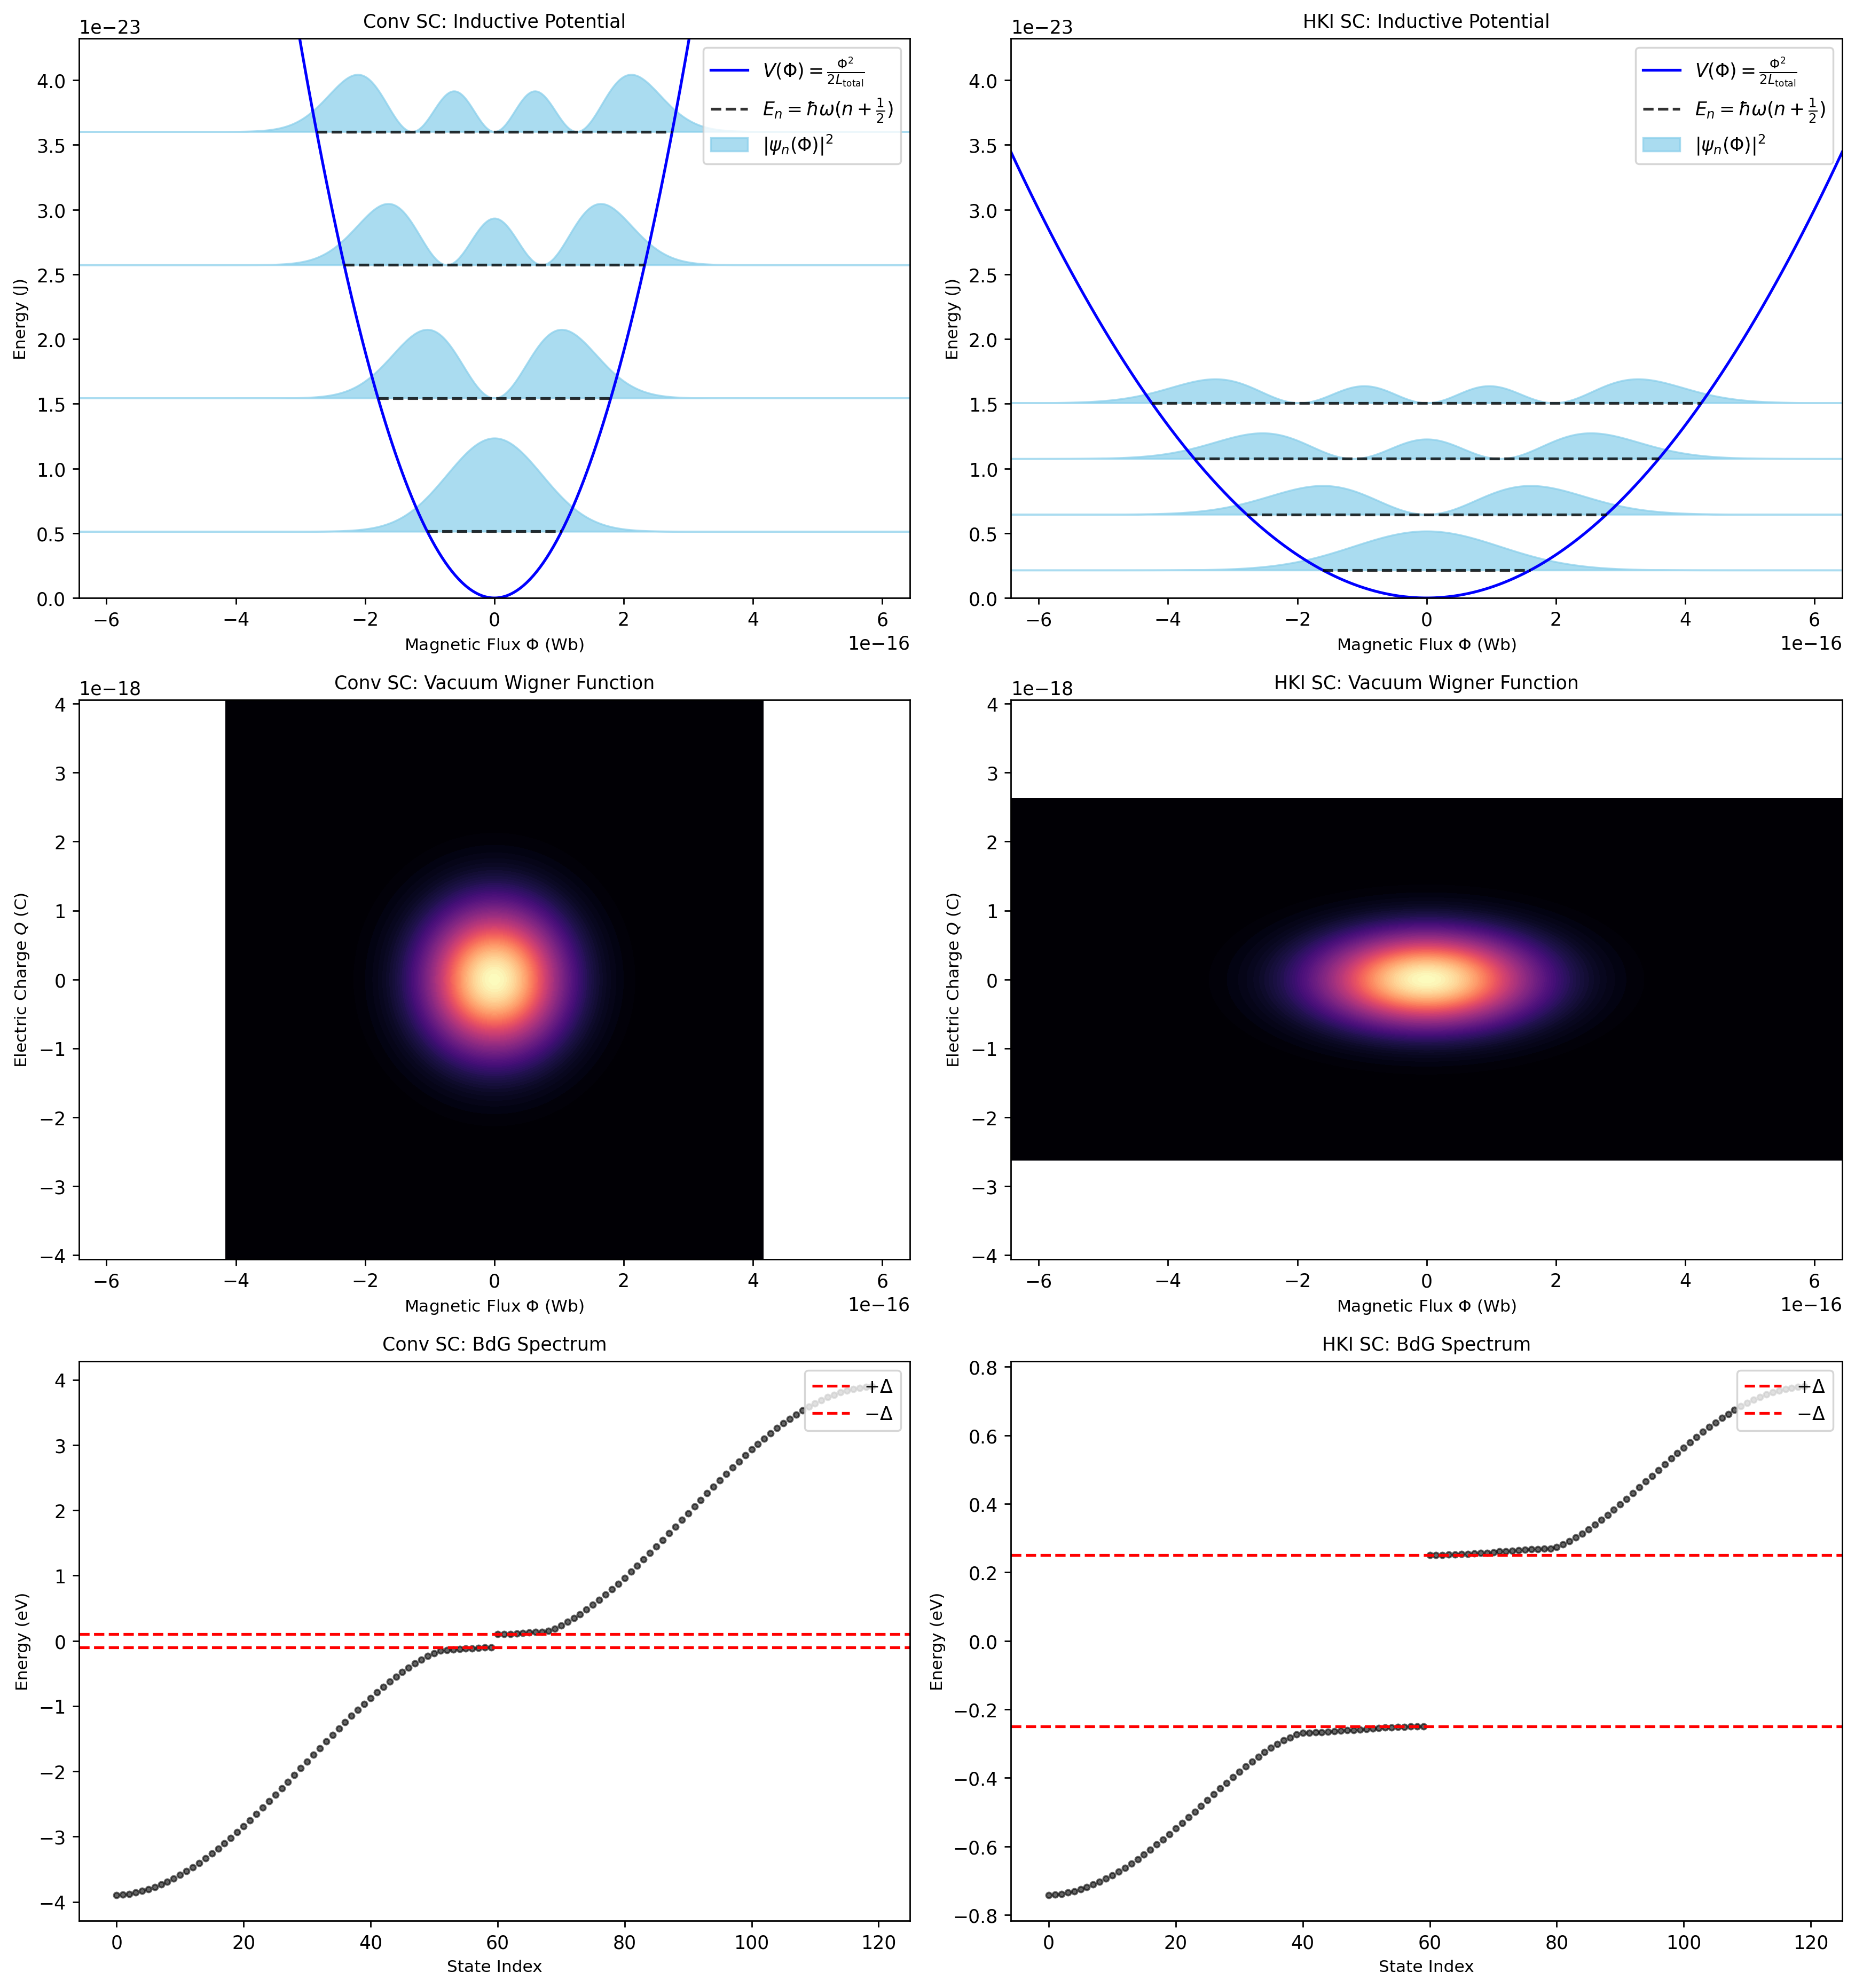

In [12]:
"""
This script computes a macroscopic and microscopic evaluation of a Quantum Harmonic Oscillator (QHO)
employing conventional and High Kinetic Inductance (HKI) superconductors. The resulting figure
resolves the parabolic potential energy landscapes with discrete harmonic wavefunctions, QuTiP Wigner
phase-space deformations, and Kwant Bogoliubov-de Gennes (BdG) tight-binding spectra.
"""

import warnings
import math
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
import kwant
import tinyarray as ta
import scipy.constants as const
from scipy.special import eval_hermite

warnings.filterwarnings("ignore", category=kwant.KwantDeprecationWarning)

# Macroscopic LC Control Knobs
CAPACITANCE = 100e-15                # (C) Total capacitance in Farads
GEOMETRIC_INDUCTANCE = 1e-9          # (L_geo) Geometric inductance in Henrys
KINETIC_INDUCTANCE_CONV = 0.05e-9    # (L_kin,conv) Kinetic inductance of standard SC
KINETIC_INDUCTANCE_HKI = 5e-9        # (L_kin,HKI) Kinetic inductance of HKI SC
HILBERT_SPACE_DIM = 30               # Dimension of the QuTiP Hilbert space

# Microscopic BdG Control Knobs
CHAIN_LENGTH = 60                    # Number of lattice sites for the BdG model

HOPPING_CONV = 1.0                   # (t_hop) Tight-binding hopping energy for Conv SC (eV)
MU_CONV = 0.1                        # (mu) Chemical potential for Conv SC (eV)
GAP_CONV = 0.1                       # (Delta) Superconducting gap for Conv SC (eV)

HOPPING_HKI = 0.2                    # (t_hop) Suppressed hopping for disordered HKI SC (eV)
MU_HKI = 0.1                         # (mu) Chemical potential for HKI SC (eV)
GAP_HKI = 0.25                       # (Delta) Enlarged gap for HKI SC (eV)

# Matplotlib Configuration
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['font.weight'] = 'normal'
plt.rcParams['figure.dpi'] = 250
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['axes.labelsize'] = 9


def build_superconducting_wire(length, t_hop, mu, delta):
    """
    Constructs a 1D Kwant lattice utilizing the Nambu spinor basis
    to resolve the superconducting quasiparticle gap.
    """
    tau_z = ta.array([[1, 0], [0, -1]])
    tau_x = ta.array([[0, 1], [1, 0]])

    syst = kwant.Builder()
    lat = kwant.lattice.chain(a=1, norbs=2)

    syst[(lat(x) for x in range(length))] = (2.0 * t_hop - mu) * tau_z + delta * tau_x
    syst[kwant.builder.HoppingKind((1,), lat, lat)] = -t_hop * tau_z

    return syst.finalized()


def calculate_qho_stats(total_inductance, capacitance):
    """
    Computes the zero-point fluctuation amplitudes for a given LC resonator.
    """
    omega = 1.0 / np.sqrt(total_inductance * capacitance)
    z0 = np.sqrt(total_inductance / capacitance)

    phi_zpf = np.sqrt(const.hbar * z0 / 2.0)
    q_zpf = np.sqrt(const.hbar / (2.0 * z0))

    return phi_zpf, q_zpf, omega


def plot_parabolic_potential(ax, total_inductance, omega, phi_zpf, max_phi, max_energy_limit, title):
    """
    Plots the macroscopic inductive parabolic potential alongside the
    probability densities for multiple discrete harmonic energy levels.
    """
    phi_grid = np.linspace(-max_phi, max_phi, 500)
    potential_energy = (phi_grid ** 2) / (2.0 * total_inductance)

    ax.plot(phi_grid, potential_energy, 'b-', label=r'$V(\Phi) = \frac{\Phi^2}{2L_{\mathrm{total}}}$')

    # Establish a uniform scaling factor based on the fundamental n=0 peak density
    peak_density_0 = 1.0 / (np.sqrt(2.0 * np.pi) * phi_zpf)
    scale_factor = (0.7 * const.hbar * omega) / peak_density_0

    num_levels = 4
    for n in range(num_levels):
        e_n = const.hbar * omega * (n + 0.5)
        phi_turn = np.sqrt(2.0 * total_inductance * e_n)

        label_str_e = r'$E_n = \hbar \omega (n + \frac{1}{2})$' if n == 0 else None
        ax.plot([-phi_turn, phi_turn], [e_n, e_n], 'k--', alpha=0.8, label=label_str_e)

        # Calculate normalized probability density utilizing Hermite polynomials
        xi = phi_grid / (np.sqrt(2.0) * phi_zpf)
        norm_sq = 1.0 / (np.sqrt(2.0 * np.pi) * phi_zpf * (2.0**n) * math.factorial(n))
        prob_density = norm_sq * (eval_hermite(n, xi)**2) * np.exp(-xi**2)

        scaled_density = e_n + prob_density * scale_factor

        label_str_psi = r'$|\psi_n(\Phi)|^2$' if n == 0 else None
        ax.fill_between(phi_grid, e_n, scaled_density, color='skyblue', alpha=0.7, label=label_str_psi)

    ax.set_xlim(-max_phi, max_phi)
    ax.set_ylim(0, max_energy_limit)
    ax.set_xlabel(r'Magnetic Flux $\Phi$ (Wb)')
    ax.set_ylabel('Energy (J)')
    ax.set_title(title)
    ax.ticklabel_format(style='sci', axis='both', scilimits=(0, 0))
    ax.legend(loc='upper right')


def plot_wigner_function(ax, phi_zpf, q_zpf, max_phi, max_q, title):
    """
    Generates a QuTiP Wigner function for the QHO ground state and maps
    the dimensionless phase space to physical flux and charge variables.
    """
    psi0 = qt.basis(HILBERT_SPACE_DIM, 0)
    xvec = np.linspace(-4, 4, 150)
    wigner_dist = qt.wigner(psi0, xvec, xvec)

    phi_grid = xvec * np.sqrt(2) * phi_zpf
    q_grid = xvec * np.sqrt(2) * q_zpf

    contour = ax.contourf(phi_grid, q_grid, wigner_dist, levels=100, cmap='magma')
    ax.set_xlim(-max_phi, max_phi)
    ax.set_ylim(-max_q, max_q)
    ax.set_xlabel(r'Magnetic Flux $\Phi$ (Wb)')
    ax.set_ylabel(r'Electric Charge $Q$ (C)')
    ax.set_title(title)
    ax.ticklabel_format(style='sci', axis='both', scilimits=(0, 0))
    return contour


def plot_bdg_spectrum(ax, eigenvalues, delta, title):
    """
    Plots the microscopic quasiparticle energy spectrum from the Kwant Hamiltonian.
    """
    ax.plot(eigenvalues, 'ko', markersize=3, alpha=0.6)
    ax.axhline(delta, color='red', linestyle='--', label=r'$+\Delta$')
    ax.axhline(-delta, color='red', linestyle='--', label=r'$-\Delta$')
    ax.set_xlabel('State Index')
    ax.set_ylabel('Energy (eV)')
    ax.set_title(title)
    ax.legend(loc='upper right')


def main():
    l_conv = GEOMETRIC_INDUCTANCE + KINETIC_INDUCTANCE_CONV
    l_hki = GEOMETRIC_INDUCTANCE + KINETIC_INDUCTANCE_HKI

    phi_zpf_conv, q_zpf_conv, omega_conv = calculate_qho_stats(l_conv, CAPACITANCE)
    phi_zpf_hki, q_zpf_hki, omega_hki = calculate_qho_stats(l_hki, CAPACITANCE)

    syst_conv = build_superconducting_wire(CHAIN_LENGTH, HOPPING_CONV, MU_CONV, GAP_CONV)
    syst_hki = build_superconducting_wire(CHAIN_LENGTH, HOPPING_HKI, MU_HKI, GAP_HKI)

    ham_conv = syst_conv.hamiltonian_submatrix(sparse=False)
    ham_hki = syst_hki.hamiltonian_submatrix(sparse=False)

    eig_conv = np.linalg.eigvalsh(ham_conv)
    eig_hki = np.linalg.eigvalsh(ham_hki)

    fig, axs = plt.subplots(3, 2, figsize=(14, 15))

    # Unified axis limits for strict side-by-side comparison
    max_phi = 4.0 * np.sqrt(2) * max(phi_zpf_conv, phi_zpf_hki)
    max_q = 4.0 * np.sqrt(2) * max(q_zpf_conv, q_zpf_hki)
    max_energy_limit = const.hbar * max(omega_conv, omega_hki) * 4.2

    # Row 1: Macroscopic Parabolic Potentials
    plot_parabolic_potential(axs[0, 0], l_conv, omega_conv, phi_zpf_conv, max_phi, max_energy_limit, 'Conv SC: Inductive Potential')
    plot_parabolic_potential(axs[0, 1], l_hki, omega_hki, phi_zpf_hki, max_phi, max_energy_limit, 'HKI SC: Inductive Potential')

    # Row 2: QuTiP Wigner Functions
    plot_wigner_function(axs[1, 0], phi_zpf_conv, q_zpf_conv, max_phi, max_q, 'Conv SC: Vacuum Wigner Function')
    plot_wigner_function(axs[1, 1], phi_zpf_hki, q_zpf_hki, max_phi, max_q, 'HKI SC: Vacuum Wigner Function')

    # Row 3: Kwant BdG Spectra
    plot_bdg_spectrum(axs[2, 0], eig_conv, GAP_CONV, 'Conv SC: BdG Spectrum')
    plot_bdg_spectrum(axs[2, 1], eig_hki, GAP_HKI, 'HKI SC: BdG Spectrum')

    plt.tight_layout()
    plt.show()

if __name__ == '__main__':
    main()